# Model comparison (v2 dataset): Mask R-CNN vs YOLOv8-seg vs SAM

Section 2.3 of the thesis. Every model is evaluated by the **same code**
(`utils/evaluate_predictions.py`) on the **same frozen splits** from the
predictions saved by the training notebooks 02–04 (COCO results, RLE,
score ≥ 0.05, ≤ 100 per image) and their `timing.json` (Tesla T4, batch 1,
10 warm-up + 100 timed runs).

**Model selection rule:** the highest **validation** mask AP on the std10 validation
split (COCOeval, IoU 0.50:0.95) among all Mask R-CNN runs. The training class
configuration (std10 / min400) is treated as one more hyperparameter, like the
backbone: a min400 model is scored on the std10 validation GT after its predictions
of the 10 extra classes are dropped. Test metrics are only reported, never used to
choose — the rule is encoded in `ea.select_best()`, which refuses a `test*` metric.

Contents:
1. run discovery (missing runs are skipped with a note);
2. evaluation of every run on val (selection) and test (reporting); the min400
   model also on the **std10 subset** of its classes (ids 1–10 are shared, so its
   predictions with `category_id > 10` are dropped);
3. bootstrap 95% CIs of test mask AP and a **paired bootstrap test** of the AP
   difference (best Mask R-CNN vs YOLO, same resampled images);
4. the main comparison table, the per-class AP table, SAM as a non-comparable
   upper bound (GT boxes as prompts, class-agnostic);
5. training curves of all runs; qualitative images where one model beats the other;
6. a placeholder for test-time augmentation.

**Parameters** (next cell or env vars): `VKR_RUNS_ROOT` — folder with the
downloaded run folders (default `~/Downloads`), `VKR_SAM_PRED` — SAM predictions.
Env: conda `university`, no GPU. Outputs: `outputs/comparison/`.

In [1]:
import os, sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import utils.evaluate_predictions as ep
import utils.error_analysis as ea

%matplotlib inline
ea.set_plot_style()
pd.set_option("display.width", 200, "display.max_columns", 40)

In [2]:
# ---- parameters -------------------------------------------------------------
RUNS_ROOT = Path(os.environ.get("VKR_RUNS_ROOT", "~/Downloads")).expanduser()
SAM_PRED  = Path(os.environ.get("VKR_SAM_PRED", "outputs/predictions/sam_gtboxes_std10_test.json"))
SAM_LABEL = "SAM ViT-B (GT-box prompts)"
OUT_DIR   = Path("outputs/comparison")
DATASET_ROOT = ea.DATASET_ROOT

CONF   = 0.5     # P/R/F1 and qualitative views (as in evaluate_predictions.py)
IOU    = 0.5
N_BOOT = 1000    # bootstrap resamples over test images
SEED   = 0       # the same seed -> the same resamples for every model with the same image list
N_QUAL = 4       # qualitative images per direction

OUT_DIR.mkdir(parents=True, exist_ok=True)
(OUT_DIR / "runs").mkdir(exist_ok=True)

## 1. Runs

In [3]:
runs = ea.discover_runs(RUNS_ROOT)
if not runs:
    raise SystemExit(f"No run folders under {RUNS_ROOT} — download the Drive run folders first.")
pd.DataFrame([{"run": r.name, "model": ea.FAMILY_LABEL[r.family], "backbone": r.backbone,
               "config": r.config, "files": ", ".join(sorted(r.files))} for r in runs]).set_index("run")

[*] 5 run(s) found under /Users/polina_sushko/Downloads


,model,backbone,config,files
run,,,,
v2_maskrcnn_detectron2_min400_R_101_FPN_3x,Mask R-CNN (Detectron2),R_101_FPN_3x,min400,"d2_metrics, test, timing, val"
v2_maskrcnn_detectron2_std10_R_101_FPN_3x,Mask R-CNN (Detectron2),R_101_FPN_3x,std10,"d2_metrics, test, val"
v2_maskrcnn_detectron2_std10_R_50_FPN_3x,Mask R-CNN (Detectron2),R_50_FPN_3x,std10,"d2_metrics, test, timing, val"
v2_maskrcnn_torchvision_std10,Mask R-CNN (torchvision),R50-FPN v2,std10,"test, timing, tv_history, val"
v2_yolov8seg_std10,YOLOv8s-seg,YOLOv8s-seg,std10,"test, timing, val, yolo_results"


## 2. Evaluation

Each run is evaluated on its own class configuration (val + test). A run trained on
a larger configuration (min400) gets a second row on the std10 GT: the evaluator's
loader drops its predictions of classes outside std10 and on images outside the
std10 test file (the std10 test images are a subset of the min400 test images,
same frozen split), so that row is directly comparable to the std10 models.

In [4]:
_gt_cache = {}
def gt(config, split):
    key = (config, split)
    if key not in _gt_cache:
        path = PROJECT_ROOT / "notebooks" / "outputs" / ea.CONFIG_SPLITS[config] / f"instances_{split}.json"
        _gt_cache[key] = ea.load_coco(path)
    return _gt_cache[key]

def short_label(run, eval_on):
    fam = {"maskrcnn_detectron2": "D2", "maskrcnn_torchvision": "TV", "yolov8seg": "YOLOv8s"}[run.family]
    bb = {"R_50_FPN_3x": " R50", "R_101_FPN_3x": " R101", "X_101_32x8d_FPN_3x": " X101",
          "R50-FPN v2": " R50v2"}.get(run.backbone, "")
    lab = f"{fam}{bb} {run.config}"
    if run.config != eval_on:
        lab += f"→{eval_on}"
    sfx = run.suffix.strip("_")
    return lab + (f" [{sfx}]" if sfx else "")

rows, MT, PREDS, EVALS = {}, {}, {}, {}
for run in runs:
    evals_on = [run.config] + (["std10"] if run.config != "std10" else [])
    timing = ea.read_timing(run)
    params, params_src = ea.count_params(run)
    for eval_on in evals_on:
        key = short_label(run, eval_on)
        print(f"\n=== {key}  ({run.name})")
        g_test = gt(eval_on, "test")
        preds = ea.load_preds(run.files["test"], g_test)
        ev = ea.evaluate(g_test, preds, conf=CONF, iou=IOU)
        val_ap = np.nan
        if "val" in run.files:
            g_val = gt(eval_on, "val")
            val_ap = ea.segm_ap(g_val, ea.load_preds(run.files["val"], g_val))["AP"]
        else:
            print(f"[note] {run.name}: no val_predictions.json -> excluded from model selection")
        MT[key] = ea.build_match_table(g_test, preds)
        PREDS[key], EVALS[key] = preds, ev
        # the evaluator's per-run artifacts
        ev["pr_f1"].to_csv(OUT_DIR / "runs" / f"{run.name}_on_{eval_on}_pr_f1.csv")
        ep.plot_confusion(ev["confusion"], ev["cat_names"], IOU, CONF,
                          OUT_DIR / "runs" / f"{run.name}_on_{eval_on}_confusion_matrix.png")
        macro = ev["pr_f1"].loc["macro avg"]
        rows[key] = {
            "run": run.name, "model": ea.FAMILY_LABEL[run.family], "backbone": run.backbone,
            "family": run.family, "trained_on": run.config, "eval_on": eval_on,
            "classes": len(g_test.getCatIds()),
            "val_mask_AP": val_ap,
            "test_mask_AP": ev["segm"]["AP"], "AP50": ev["segm"]["AP50"], "AP75": ev["segm"]["AP75"],
            "APs": ev["segm"]["APs"], "APm": ev["segm"]["APm"], "APl": ev["segm"]["APl"],
            "bbox_AP": ev["bbox"]["AP"],
            "agnostic_mask_AP": ea.segm_ap(g_test, preds, agnostic=True)["AP"],
            "macro_P": macro["precision"], "macro_R": macro["recall"], "macro_F1": macro["F1"],
            "mean_matched_IoU": ev["mean_iou"],
            "ms_per_img": timing.get("mean_ms", np.nan), "FPS": timing.get("fps", np.nan),
            "timing_device": timing.get("device", "n/a"),
            "params_M": params, "params_source": params_src,
        }
        print(f"val mask AP {val_ap:.4f} | test mask AP {ev['segm']['AP']:.4f} | AP50 {ev['segm']['AP50']:.4f}")


=== D2 R101 min400  (v2_maskrcnn_detectron2_min400_R_101_FPN_3x)


[i] v2_maskrcnn_detectron2_min400_R_101_FPN_3x/test_predictions.json: 41644 predictions on 1444/1444 GT images


[i] v2_maskrcnn_detectron2_min400_R_101_FPN_3x/val_predictions.json: 42363 predictions on 1443/1443 GT images


val mask AP 0.2241 | test mask AP 0.2323 | AP50 0.3874

=== D2 R101 min400→std10  (v2_maskrcnn_detectron2_min400_R_101_FPN_3x)


[!] Dropped predictions outside GT: 3120 by image_id, 13466 by category_id
[i] v2_maskrcnn_detectron2_min400_R_101_FPN_3x/test_predictions.json: 25058 predictions on 1286/1287 GT images


[!] Dropped predictions outside GT: 2799 by image_id, 13411 by category_id
[i] v2_maskrcnn_detectron2_min400_R_101_FPN_3x/val_predictions.json: 26153 predictions on 1283/1284 GT images


... (8 outputs left out)

[i] v2_maskrcnn_torchvision_std10/val_predictions.json: 27849 predictions on 1283/1284 GT images


val mask AP 0.2455 | test mask AP 0.2609 | AP50 0.4257
[note] v2_yolov8seg_std10: cannot count parameters from train/weights/best.pt (ModuleNotFoundError("No module named 'ultralytics'"))

=== YOLOv8s std10  (v2_yolov8seg_std10)
[i] v2_yolov8seg_std10/test_predictions.json: 13158 predictions on 1283/1287 GT images


[i] v2_yolov8seg_std10/val_predictions.json: 14058 predictions on 1282/1284 GT images


val mask AP 0.2406 | test mask AP 0.2427 | AP50 0.3907


**SAM** (zero-shot, `utils/sam_gt_boxes.py`): one GT box per object as the prompt,
class copied from the GT. It therefore *cannot* miss, mis-localise the box or
mis-classify — only the mask itself can be wrong. Evaluated class-agnostically
(COCOeval `useCats=0`), without bbox AP (its boxes are the GT boxes) and without
P/R/F1. It is an **upper bound for mask quality given perfect detection**, not a
competitor; compare it at most with the `agnostic_mask_AP` column of the other models.

In [5]:
if SAM_PRED.exists():
    g_test = gt("std10", "test")
    sam = ea.load_preds(SAM_PRED, g_test)
    ev = ea.evaluate(g_test, sam, agnostic=True, bbox=False, conf=CONF, iou=IOU)
    MT[SAM_LABEL] = ea.build_match_table(g_test, sam, agnostic=True)
    EVALS[SAM_LABEL] = ev
    rows[SAM_LABEL] = {"run": SAM_PRED.name, "model": "SAM (zero-shot)", "backbone": "ViT-B",
                       "family": "sam", "trained_on": "-", "eval_on": "std10", "classes": 10,
                       "val_mask_AP": np.nan, "test_mask_AP": ev["segm"]["AP"],
                       "AP50": ev["segm"]["AP50"], "AP75": ev["segm"]["AP75"],
                       "APs": ev["segm"]["APs"], "APm": ev["segm"]["APm"], "APl": ev["segm"]["APl"],
                       "bbox_AP": np.nan, "agnostic_mask_AP": ev["segm"]["AP"],
                       "macro_P": np.nan, "macro_R": np.nan, "macro_F1": np.nan,
                       "mean_matched_IoU": ev["mean_iou"], "ms_per_img": np.nan, "FPS": np.nan,
                       "timing_device": "n/a", "params_M": 93.7, "params_source": "nominal"}
    print(f"SAM: class-agnostic mask AP {ev['segm']['AP']:.4f}, mean matched IoU {ev['mean_iou']:.4f}")
else:
    print(f"[note] SAM predictions not found ({SAM_PRED}) — SAM row skipped")

tab = pd.DataFrame(rows).T
num_cols = [c for c in tab.columns if c not in ("run", "model", "backbone", "family", "trained_on",
                                                "eval_on", "timing_device", "params_source")]
tab[num_cols] = tab[num_cols].astype(float)

[i] predictions/sam_gtboxes_std10_test.json: 5043 predictions on 1287/1287 GT images


SAM: class-agnostic mask AP 0.3983, mean matched IoU 0.7636


## 3. Model selection (validation only)

Candidates for "the Mask R-CNN of the thesis": every Mask R-CNN run **evaluated on
the std10 validation split**, whatever class configuration it was trained on (the
class set is a hyperparameter; a min400 model predicts the 10 standard classes as a
subset of its 20). The best overall model on the std10 validation split is reported
as well (YOLO's validation predictions are evaluated by the same COCOeval).

In [6]:
is_mrcnn_cand = tab.family.str.startswith("maskrcnn") & (tab.eval_on == "std10")
is_std10_model = (tab.family != "sam") & (tab.eval_on == "std10")

print("Rule: argmax of val_mask_AP (COCOeval segm AP@[.50:.95] on the validation split).")
print(tab.loc[tab.family != "sam", ["run", "val_mask_AP"]].sort_values("val_mask_AP", ascending=False)
      .round(4).to_string())
BEST_MRCNN = ea.select_best(tab, is_mrcnn_cand) if is_mrcnn_cand.any() else None
BEST_STD10 = ea.select_best(tab, is_std10_model) if is_std10_model.any() else None
YOLO = next((k for k in tab.index if tab.loc[k, "family"] == "yolov8seg"
             and tab.loc[k, "trained_on"] == "std10"), None)
print(f"\nselected Mask R-CNN (val): {BEST_MRCNN}")
print(f"best model on the std10 validation split overall: {BEST_STD10}")
print(f"YOLOv8-seg std10 run: {YOLO}")

Rule: argmax of val_mask_AP (COCOeval segm AP@[.50:.95] on the validation split).
                                                             run  val_mask_AP
D2 R101 min400→std10  v2_maskrcnn_detectron2_min400_R_101_FPN_3x       0.2570
D2 R101 std10          v2_maskrcnn_detectron2_std10_R_101_FPN_3x       0.2476
TV R50v2 std10                     v2_maskrcnn_torchvision_std10       0.2455
D2 R50 std10            v2_maskrcnn_detectron2_std10_R_50_FPN_3x       0.2437
YOLOv8s std10                                 v2_yolov8seg_std10       0.2406
D2 R101 min400        v2_maskrcnn_detectron2_min400_R_101_FPN_3x       0.2241

selected Mask R-CNN (val): D2 R101 min400→std10
best model on the std10 validation split overall: D2 R101 min400→std10
YOLOv8-seg std10 run: YOLOv8s std10


## 4. Bootstrap CIs and the paired significance test

Test images are resampled with replacement; AP is recomputed exactly from
COCOeval's per-detection matches (`ea.build_match_table`). All models evaluated
on the same GT share the same resamples (same seed and image list), so the
**paired** test of a difference resamples the same images for both models —
much tighter than comparing two independent CIs. Two-sided p-value:
2 · min(P(Δ* ≤ 0), P(Δ* ≥ 0)).

Note: the bootstrap distribution of AP is shifted *upwards* relative to the point
estimate (`test_AP_boot_bias`; the interpolated precision is a running max, so
resampling noise inflates it), so the percentile CI (`ci_lo/ci_hi`) is
asymmetric; the bias-corrected *basic* interval (`basic_lo/basic_hi`) is stored
too. The SE and the paired test of a difference are essentially unaffected
(the bias is common to both models).

In [7]:
ci_rows = {}
for key, mt in MT.items():
    assert abs(ea.ap_from_weights(mt)[0] - tab.loc[key, "test_mask_AP"]) < 1e-12, key
    boot = ea.bootstrap_ap(mt, n_boot=N_BOOT, seed=SEED)
    ci = ea.ci_summary(tab.loc[key, "test_mask_AP"], boot.AP)
    ci50 = ea.ci_summary(tab.loc[key, "AP50"], boot.AP50)
    ci_rows[key] = {"test_AP_se": ci["boot_se"], "test_AP_ci_lo": ci["ci_lo"], "test_AP_ci_hi": ci["ci_hi"],
                    "test_AP_basic_lo": ci["basic_lo"], "test_AP_basic_hi": ci["basic_hi"],
                    "test_AP_boot_bias": ci["boot_bias"],
                    "AP50_ci_lo": ci50["ci_lo"], "AP50_ci_hi": ci50["ci_hi"]}
tab = tab.join(pd.DataFrame(ci_rows).T.astype(float))
print(tab[["test_mask_AP", "test_AP_se", "test_AP_ci_lo", "test_AP_ci_hi", "test_AP_boot_bias",
           "test_AP_basic_lo", "test_AP_basic_hi"]].round(4).to_string())

                            test_mask_AP  test_AP_se  test_AP_ci_lo  test_AP_ci_hi  test_AP_boot_bias  test_AP_basic_lo  test_AP_basic_hi
D2 R101 min400                    0.2323      0.0086         0.2213         0.2549             0.0052            0.2096            0.2433
D2 R101 min400→std10              0.2665      0.0144         0.2462         0.3022             0.0063            0.2307            0.2867
D2 R101 std10                     0.2627      0.0139         0.2428         0.2970             0.0062            0.2284            0.2827
D2 R50 std10                      0.2466      0.0140         0.2261         0.2830             0.0072            0.2103            0.2671
TV R50v2 std10                    0.2609      0.0133         0.2417         0.2935             0.0061            0.2282            0.2801
YOLOv8s std10                     0.2427      0.0140         0.2220         0.2771             0.0058            0.2082            0.2633
SAM ViT-B (GT-box prompts)        

In [8]:
pairs = []
if BEST_MRCNN and YOLO:
    pairs.append((BEST_MRCNN, YOLO, "selected Mask R-CNN vs YOLOv8-seg"))
fam = tab.family
is_mrcnn_std10 = fam.str.startswith("maskrcnn") & (tab.trained_on == "std10") & (tab.eval_on == "std10")
d2_std10 = [k for k in tab.index if fam[k] == "maskrcnn_detectron2" and is_mrcnn_std10[k]]
r50 = [k for k in d2_std10 if tab.loc[k, "backbone"] == "R_50_FPN_3x"]
r101 = [k for k in d2_std10 if tab.loc[k, "backbone"] == "R_101_FPN_3x"]
if r50 and r101:
    pairs.append((r101[0], r50[0], "backbone: R101 vs R50 (Detectron2, std10)"))
# implementation: the best Detectron2 vs torchvision, per (training config, evaluation GT)
for c, e in sorted(set(zip(tab.trained_on, tab.eval_on))):
    d2 = [k for k in tab.index if fam[k] == "maskrcnn_detectron2" and tab.loc[k, "trained_on"] == c
          and tab.loc[k, "eval_on"] == e]
    tv = [k for k in tab.index if fam[k] == "maskrcnn_torchvision" and tab.loc[k, "trained_on"] == c
          and tab.loc[k, "eval_on"] == e]
    if d2 and tv:
        pairs.append((ea.select_best(tab, tab.index.isin(d2)), tv[0],
                      f"implementation: Detectron2 vs torchvision ({c} models on {e})"))
# class configuration: a min400 model on the std10 subset vs the same family/backbone trained on std10
for k in tab.index:
    if tab.loc[k, "trained_on"] != "std10" and tab.loc[k, "eval_on"] == "std10" and fam[k] != "sam":
        same = [j for j in tab.index if is_mrcnn_std10[j] and fam[j] == fam[k]
                and tab.loc[j, "backbone"] == tab.loc[k, "backbone"]]
        if same:
            pairs.append((k, same[0], f"class config: {tab.loc[k, 'trained_on']} vs std10 "
                                      f"({tab.loc[k, 'model']}, std10 subset)"))

sig_rows = []
for a, b, what in pairs:
    for metric in ["AP", "AP50"]:
        r = ea.paired_bootstrap(MT[a], MT[b], n_boot=N_BOOT, seed=SEED, metric=metric)
        sig_rows.append({"comparison": what, "model_a": a, "model_b": b, **r})
sig = pd.DataFrame(sig_rows)
if len(sig):
    sig["significant_5pct"] = sig.p_value < 0.05
    sig.to_csv(OUT_DIR / "paired_bootstrap.csv", index=False)
    print(sig.drop(columns=["n_boot"]).round(4).to_string(index=False))
else:
    print("[note] no comparable pair of runs present — paired test skipped")

                                                           comparison              model_a        model_b metric   delta  boot_se   ci_lo  ci_hi  p_value  n_images  significant_5pct
                                    selected Mask R-CNN vs YOLOv8-seg D2 R101 min400→std10  YOLOv8s std10     AP  0.0238   0.0107  0.0022 0.0449    0.030      1287              True
                                    selected Mask R-CNN vs YOLOv8-seg D2 R101 min400→std10  YOLOv8s std10   AP50  0.0365   0.0138  0.0097 0.0641    0.006      1287              True
                            backbone: R101 vs R50 (Detectron2, std10)        D2 R101 std10   D2 R50 std10     AP  0.0161   0.0085 -0.0040 0.0317    0.090      1287             False
                            backbone: R101 vs R50 (Detectron2, std10)        D2 R101 std10   D2 R50 std10   AP50  0.0259   0.0084  0.0085 0.0409    0.002      1287              True
    implementation: Detectron2 vs torchvision (std10 models on std10)        D2 R101 std10

## 5. Main comparison table

`role`: *selected* — the Mask R-CNN chosen by validation AP (on the std10
validation split); *comparison* — other models on the same 10-class test set
(min400 models on the std10 subset of their classes); *other config* — min400
models on their own 20 classes (not comparable with the 10-class rows);
*upper bound* — SAM.

In [9]:
def role(k):
    if tab.loc[k, "family"] == "sam":
        return "upper bound — non-comparable (GT boxes, class-agnostic)"
    if k == BEST_MRCNN:
        return "selected (best val mask AP)"
    if tab.loc[k, "eval_on"] != "std10":
        return (f"other config ({int(tab.loc[k, 'classes'])} classes) — "
                "not comparable with std10 rows")
    if tab.loc[k, "trained_on"] != "std10":
        return f"comparison ({tab.loc[k, 'trained_on']} model on the std10 subset)"
    return "comparison"

tab["role"] = [role(k) for k in tab.index]
main_cols = ["model", "backbone", "trained_on", "eval_on", "classes", "val_mask_AP",
             "test_mask_AP", "test_AP_ci_lo", "test_AP_ci_hi", "AP50", "AP75", "APs", "APm", "APl",
             "bbox_AP", "agnostic_mask_AP", "macro_P", "macro_R", "macro_F1", "mean_matched_IoU",
             "ms_per_img", "FPS", "timing_device", "params_M", "params_source", "role", "run"]
order = sorted(tab.index, key=lambda k: (tab.loc[k, "family"] == "sam", tab.loc[k, "eval_on"] != "std10",
                                          -tab.loc[k, "test_mask_AP"]))
main = tab.loc[order, main_cols]
main.to_csv(OUT_DIR / "main_comparison.csv")
not_t4 = main[(main.timing_device != "n/a") & ~main.timing_device.str.contains("T4")]
if len(not_t4):
    print("[!] timing not measured on a T4 for:", list(not_t4.index))
show = main.drop(columns=["run", "timing_device", "params_source"]).copy()
show["test_mask_AP"] = [f"{v:.4f} [{lo:.4f}, {hi:.4f}]" for v, lo, hi in
                        zip(main.test_mask_AP, main.test_AP_ci_lo, main.test_AP_ci_hi)]
show = show.drop(columns=["test_AP_ci_lo", "test_AP_ci_hi"])
show.round(4)

,model,backbone,trained_on,eval_on,classes,val_mask_AP,test_mask_AP,AP50,AP75,APs,APm,APl,bbox_AP,agnostic_mask_AP,macro_P,macro_R,macro_F1,mean_matched_IoU,ms_per_img,FPS,params_M,role
D2 R101 min400→std10,Mask R-CNN (Detectron2),R_101_FPN_3x,min400,std10,10.0,0.2570,"0.2665 [0.2462, 0.3022]",0.4272,0.2861,0.0309,0.1075,0.3526,0.2893,0.2445,0.4909,0.4551,0.4588,0.7900,223.9436,4.4654,63.0655,selected (best val mask AP)
D2 R101 std10,Mask R-CNN (Detectron2),R_101_FPN_3x,std10,std10,10.0,0.2476,"0.2627 [0.2428, 0.2970]",0.4305,0.2728,0.0280,0.1040,0.3463,0.2932,0.2472,0.4588,0.4955,0.4704,0.7901,NaN,NaN,63.0117,comparison
TV R50v2 std10,Mask R-CNN (torchvision),R50-FPN v2,std10,std10,10.0,0.2455,"0.2609 [0.2417, 0.2935]",0.4257,0.2803,0.0186,0.1058,0.3366,0.2909,0.2441,0.3652,0.5131,0.4201,0.7881,231.0261,4.3285,45.9288,comparison
D2 R50 std10,Mask R-CNN (Detectron2),R_50_FPN_3x,std10,std10,10.0,0.2437,"0.2466 [0.2261, 0.2830]",0.4046,0.2700,0.0152,0.0996,0.3285,0.2659,0.2359,0.4696,0.4597,0.4561,0.7860,182.7257,5.4727,44.0196,comparison
YOLOv8s std10,YOLOv8s-seg,YOLOv8s-seg,std10,std10,10.0,0.2406,"0.2427 [0.2220, 0.2771]",0.3907,0.2534,0.0340,0.1115,0.3155,0.2847,0.2565,0.6348,0.3268,0.4183,0.8146,21.7109,46.0598,11.8000,comparison
D2 R101 min400,Mask R-CNN (Detectron2),R_101_FPN_3x,min400,min400,20.0,0.2241,"0.2323 [0.2213, 0.2549]",0.3874,0.2444,0.0648,0.1625,0.2964,0.2487,0.2382,0.4257,0.4470,0.4250,0.7946,223.9436,4.4654,63.0655,other config (20 classes) — not comparable wit...
SAM ViT-B (GT-box prompts),SAM (zero-shot),ViT-B,-,std10,10.0,NaN,"0.3983 [0.3864, 0.4121]",0.7526,0.3647,0.3054,0.4054,0.4138,NaN,0.3983,NaN,NaN,NaN,0.7636,NaN,NaN,93.7000,"upper bound — non-comparable (GT boxes, class-..."


### Per-class mask AP

Rows = the 10 std10 classes, columns = every model evaluated on the std10 test
set (SAM excluded: class-agnostic). The min400 model on its own 20 classes is
saved separately (`per_class_ap_min400_20cls.csv`).

            n_test_gt  D2 R101 min400→std10  D2 R101 std10  TV R50v2 std10  D2 R50 std10  YOLOv8s std10
toilet             39                 0.579          0.631           0.680         0.600          0.526
bed               222                 0.289          0.293           0.296         0.278          0.306
sofa              325                 0.282          0.271           0.283         0.271          0.256
bathtub            22                 0.293          0.253           0.227         0.257          0.276
table            1131                 0.260          0.253           0.244         0.240          0.246
dresser           101                 0.267          0.262           0.218         0.202          0.228
chair            2651                 0.215          0.216           0.217         0.203          0.225
nightstand         62                 0.232          0.216           0.197         0.186          0.161
bookshelf         109                 0.180          0.159      

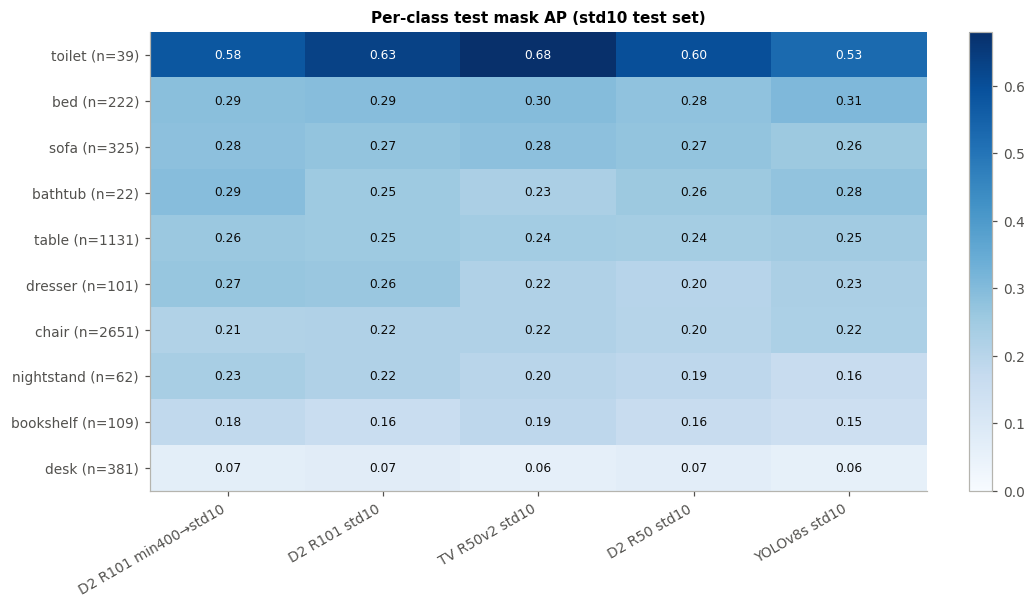

In [10]:
std_keys = [k for k in order if tab.loc[k, "eval_on"] == "std10" and tab.loc[k, "family"] != "sam"]
pc = pd.DataFrame({k: EVALS[k]["per_class"] for k in std_keys})
pc = pc.loc[pc.mean(axis=1).sort_values(ascending=False).index]
n_gt = pd.Series([a["category_id"] for a in gt("std10", "test").dataset["annotations"]]).map(
    ea.class_names(gt("std10", "test"))).value_counts()
pc.insert(0, "n_test_gt", n_gt.reindex(pc.index))
pc.to_csv(OUT_DIR / "per_class_ap.csv")
for k in tab.index:
    if tab.loc[k, "eval_on"] != "std10":
        pd.Series(EVALS[k]["per_class"], name=k).sort_values(ascending=False).to_frame().to_csv(
            OUT_DIR / f"per_class_ap_{tab.loc[k, 'eval_on']}_{int(tab.loc[k, 'classes'])}cls.csv")
print(pc.round(3).to_string())

M = pc.drop(columns="n_test_gt").values
fig, ax = plt.subplots(figsize=(1.3 * M.shape[1] + 3, 0.42 * M.shape[0] + 1.4))
im = ax.imshow(M, cmap="Blues", vmin=0, vmax=max(np.nanmax(M), 1e-6), aspect="auto")
ax.set_xticks(range(M.shape[1]), pc.columns[1:], rotation=30, ha="right")
ax.set_yticks(range(M.shape[0]), [f"{c} (n={n})" for c, n in zip(pc.index, pc.n_test_gt)])
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if M[i, j] > 0.6 * np.nanmax(M) else "#0b0b0b")
ax.grid(False)
ax.set_title("Per-class test mask AP (std10 test set)")
fig.colorbar(im, fraction=0.03)
fig.tight_layout(); fig.savefig(OUT_DIR / "per_class_ap.png"); plt.show()

(not plotted: SAM ViT-B (GT-box prompts), class-agnostic upper bound, AP 0.398)


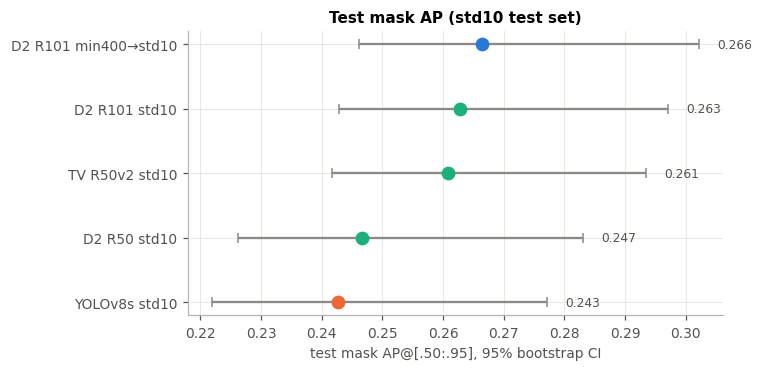

In [11]:
# headline figure: test mask AP with 95% CI, std10 rows (SAM left out: not comparable)
fig_keys = [k for k in order if tab.loc[k, "eval_on"] == "std10" and tab.loc[k, "family"] != "sam"]
if SAM_LABEL in tab.index:
    print(f"(not plotted: {SAM_LABEL}, class-agnostic upper bound, AP {tab.loc[SAM_LABEL, 'test_mask_AP']:.3f})")
fig, ax = plt.subplots(figsize=(7, 0.45 * len(fig_keys) + 1.2))
y = np.arange(len(fig_keys))[::-1]
for yi, k in zip(y, fig_keys):
    r = tab.loc[k]
    sam_row = r.family == "sam"
    col = ea.GREY if sam_row else (ea.PALETTE[0] if k == BEST_MRCNN else ea.PALETTE[1] if r.family == "yolov8seg"
                                   else ea.PALETTE[2])
    ax.errorbar(r.test_mask_AP, yi, xerr=[[r.test_mask_AP - r.test_AP_ci_lo], [r.test_AP_ci_hi - r.test_mask_AP]],
                fmt="D" if sam_row else "o", ms=8, color=col, ecolor="#8a8985", capsize=3, lw=1.5)
    ax.text(r.test_AP_ci_hi + 0.003, yi, f"{r.test_mask_AP:.3f}", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, [k + ("  (class-agnostic, GT boxes)" if tab.loc[k, "family"] == "sam" else "") for k in fig_keys])
ax.set_xlabel("test mask AP@[.50:.95], 95% bootstrap CI")
ax.set_title("Test mask AP (std10 test set)")
fig.tight_layout(); fig.savefig(OUT_DIR / "test_mask_ap_ci.png"); plt.show()

## 6. Training curves

Validation mask AP per epoch from each run's log: Detectron2 `metrics.json`
(COCOeval, every nominal epoch), torchvision `history.csv` (COCOeval), YOLO
`results.csv` — **Ultralytics' own** mask mAP50-95 (a different evaluator and
interpolation; only the trend is comparable, dashed). The min400 curve is
over its 20 classes. Circles mark the best epoch.

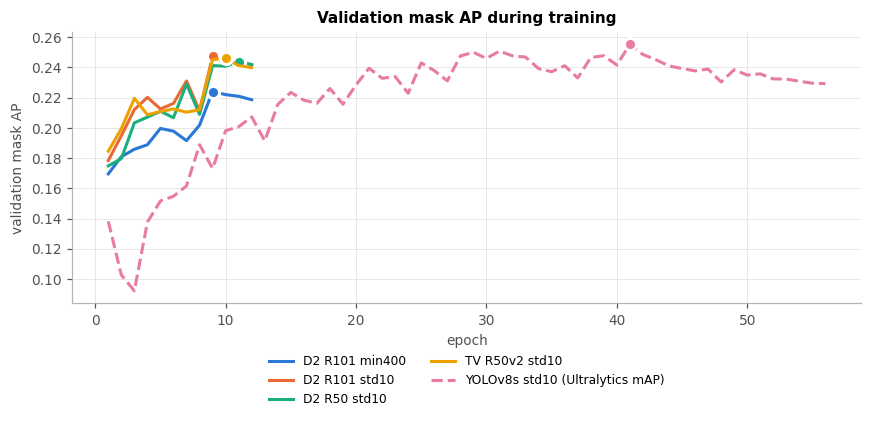

In [12]:
curves = []
for run in runs:
    c = ea.load_val_curve(run)
    if c.empty:
        print(f"[note] {run.name}: no training log found — no curve")
        continue
    c.insert(0, "run", run.name)
    curves.append(c)
if curves:
    curves = pd.concat(curves, ignore_index=True)
    curves.to_csv(OUT_DIR / "training_curves.csv", index=False)
    fig, ax = plt.subplots(figsize=(8, 4))
    for i, (name, c) in enumerate(curves.groupby("run", sort=True)):
        run = next(r for r in runs if r.name == name)
        ls = "--" if c.source.iloc[0].startswith("Ultralytics") else "-"
        col = ea.PALETTE[i % len(ea.PALETTE)]
        ax.plot(c.epoch, c.val_mask_AP, ls, color=col, label=short_label(run, run.config)
                + (" (Ultralytics mAP)" if ls == "--" else ""))
        b = c.val_mask_AP.idxmax()
        ax.plot(c.epoch[b], c.val_mask_AP[b], "o", ms=8, color=col, mec="white", mew=2)
    ax.set_xlabel("epoch"); ax.set_ylabel("validation mask AP")
    ax.set_title("Validation mask AP during training")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, fontsize=8)
    fig.tight_layout(); fig.savefig(OUT_DIR / "training_curves.png"); plt.show()

## 7. Qualitative: where Mask R-CNN beats YOLO and vice versa

Selection rule (printed below): per-image F1 at score ≥ `CONF`, mask IoU ≥ 0.5,
class-aware COCOeval matching, for the selected Mask R-CNN and for YOLO on the
same test images; only images with ≥ 2 GT objects; ranked by
ΔF1 = F1(Mask R-CNN) − F1(YOLO), ties broken by the number of GT objects.
Columns: GT | Mask R-CNN | YOLO (masks with score ≥ `CONF`).

selection rule: per-image F1 (score >= 0.5, IoU >= 0.5, class-aware), images with >= 2 GT (1057 of 1287); dF1 = F1(D2 R101 min400→std10) - F1(YOLOv8s std10); ties -> more GT
images where D2 R101 min400→std10 is better: 535, YOLOv8s std10 better: 352, equal: 400



mrcnn_better:
          n_gt_a   f1_a  f1_b    dF1
image_id                            
157          2.0  1.000   0.0  1.000
8350         2.0  1.000   0.0  1.000
10137        3.0  0.857   0.0  0.857
10054       18.0  0.842   0.0  0.842


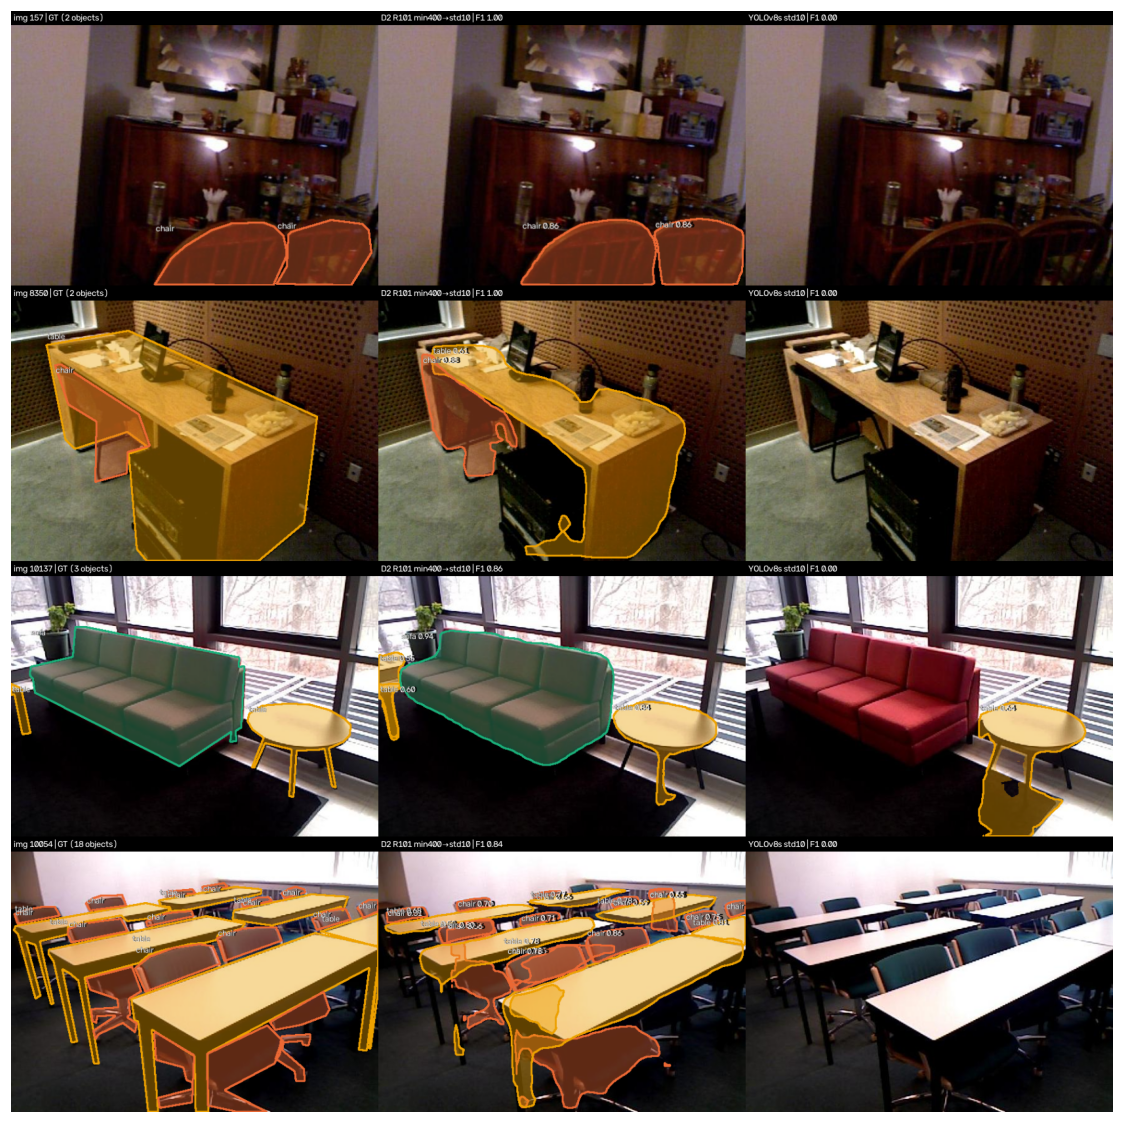


yolo_better:
          n_gt_a   f1_a   f1_b    dF1
image_id                             
7290         2.0  0.333  1.000 -0.667
1727         2.0  0.000  0.667 -0.667
1823         2.0  0.000  0.667 -0.667
1946         2.0  0.400  1.000 -0.600


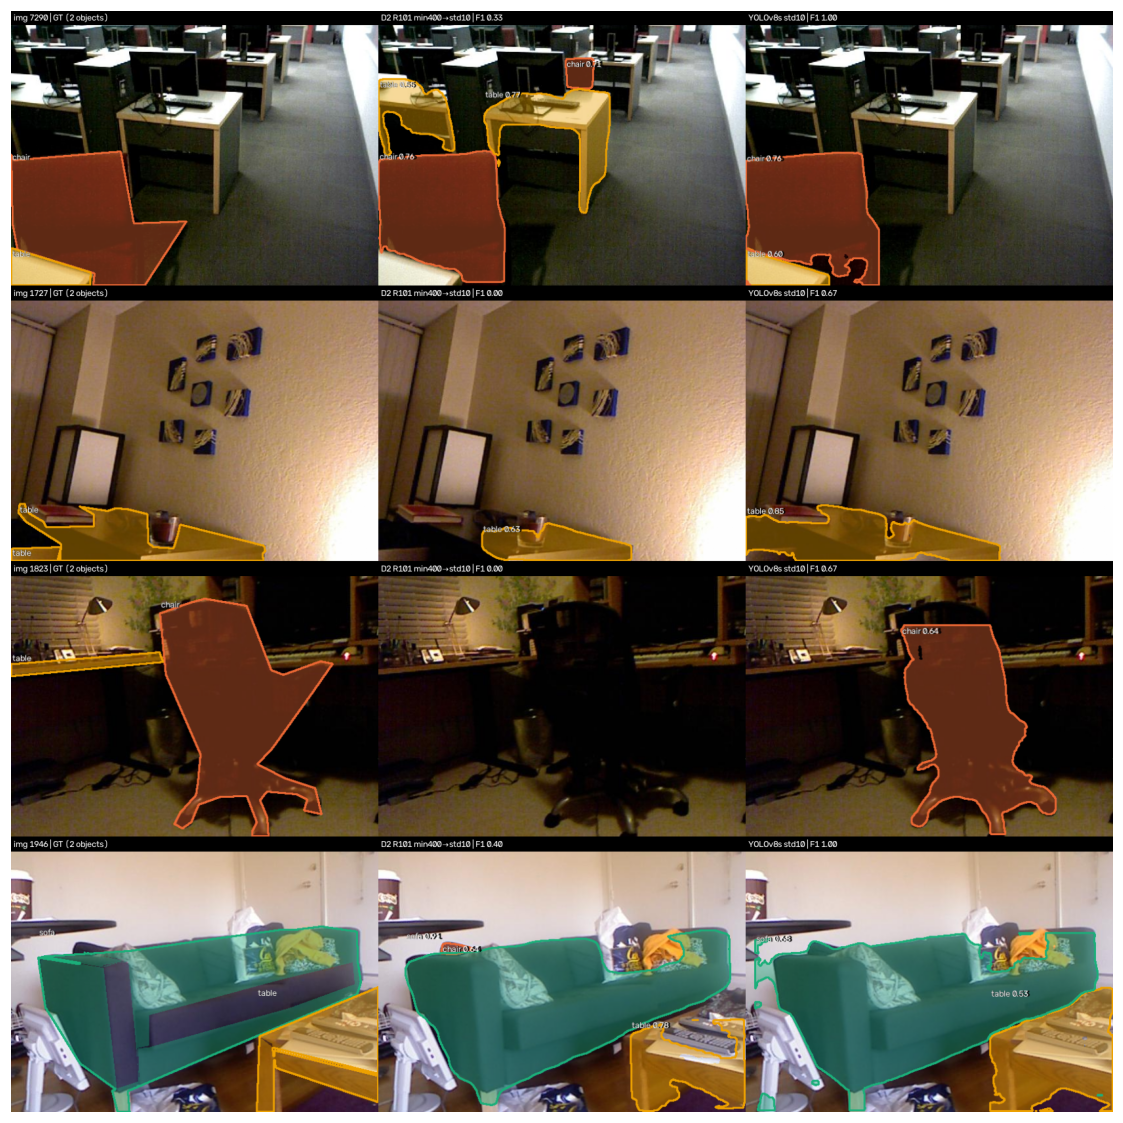

In [13]:
if BEST_MRCNN and YOLO:
    a, b = BEST_MRCNN, YOLO
    pa, pb = ea.per_image_stats(MT[a], conf=CONF), ea.per_image_stats(MT[b], conf=CONF)
    q = pa.join(pb, lsuffix="_a", rsuffix="_b")
    q["dF1"] = q.f1_a - q.f1_b
    elig = q[q.n_gt_a >= 2]
    print(f"selection rule: per-image F1 (score >= {CONF}, IoU >= 0.5, class-aware), "
          f"images with >= 2 GT ({len(elig)} of {len(q)}); dF1 = F1({a}) - F1({b}); ties -> more GT")
    print(f"images where {a} is better: {(q.dF1 > 0).sum()}, {b} better: {(q.dF1 < 0).sum()}, "
          f"equal: {(q.dF1 == 0).sum()}")
    by_img = {k: {} for k in (a, b)}
    for k in (a, b):
        for p in PREDS[k]:
            by_img[k].setdefault(p["image_id"], []).append(p)
    g_test = gt("std10", "test")
    for tag, sel in [("mrcnn_better", elig.sort_values(["dF1", "n_gt_a"], ascending=[False, False]).head(N_QUAL)),
                     ("yolo_better", elig.sort_values(["dF1", "n_gt_a"], ascending=[True, False]).head(N_QUAL))]:
        tiles = []
        for img_id, r in sel.iterrows():
            tiles.append(ea.render_predictions_tile(g_test, [], img_id,
                         f"img {img_id} | GT ({int(r.n_gt_a)} objects)", show_gt=True, root=DATASET_ROOT))
            tiles.append(ea.render_predictions_tile(g_test, by_img[a].get(img_id, []), img_id,
                         f"{a} | F1 {r.f1_a:.2f}", conf=CONF, root=DATASET_ROOT))
            tiles.append(ea.render_predictions_tile(g_test, by_img[b].get(img_id, []), img_id,
                         f"{b} | F1 {r.f1_b:.2f}", conf=CONF, root=DATASET_ROOT))
        path = ea.save_montage(tiles, OUT_DIR / f"qualitative_{tag}.png", ncols=3)
        sel.to_csv(OUT_DIR / f"qualitative_{tag}_manifest.csv")
        print(f"\n{tag}:"); print(sel[["n_gt_a", "f1_a", "f1_b", "dF1"]].round(3).to_string())
        im = plt.imread(path)
        plt.figure(figsize=(13, 13 * im.shape[0] / im.shape[1])); plt.imshow(im); plt.axis("off"); plt.show()
else:
    print("[skip] needs both the selected Mask R-CNN and a YOLOv8-seg std10 run")

## 8. Test-time augmentation (placeholder)

TTA needs the model and a GPU (Detectron2 `GeneralizedRCNNWithTTA`: horizontal
flip + multi-scale `MIN_SIZE_TEST` ∈ {400 … 1000}, box/mask fusion), so it is
not run here. If it is run in Colab for the selected Detectron2 model, save its
predictions as `test_predictions_tta.json` (+ `val_predictions_tta.json` and a
`timing_tta.json` measured with the same protocol) in the run folder and report
it as a **separate row** "D2 R… std10 + TTA": same evaluator, same bootstrap and a
paired test against the plain model; its latency is several times higher, so the
row must carry its own ms/img. TTA does not change model selection (made on the
plain models' validation AP).

In [14]:
print("Outputs in", OUT_DIR)
for p in sorted(OUT_DIR.iterdir()):
    if p.is_file():
        print(f"  {p.name:45s} {p.stat().st_size/1024:8.1f} KB")
print(f"  runs/  ({len(list((OUT_DIR / 'runs').iterdir()))} per-run evaluator files)")

Outputs in outputs/comparison
  main_comparison.csv                                3.2 KB
  paired_bootstrap.csv                               1.6 KB
  per_class_ap.csv                                   1.1 KB
  per_class_ap.png                                 111.9 KB
  per_class_ap_min400_20cls.csv                      0.5 KB
  qualitative_mrcnn_better.png                    3548.2 KB
  qualitative_mrcnn_better_manifest.csv              0.3 KB
  qualitative_yolo_better.png                     3363.0 KB
  qualitative_yolo_better_manifest.csv               0.3 KB
  test_mask_ap_ci.png                               43.3 KB
  training_curves.csv                                7.1 KB
  training_curves.png                               71.1 KB
  runs/  (12 per-run evaluator files)
